In [ ]:
# 0 
# Initialization
using Plots
using Distributions, Random, Statistics
using LinearAlgebra, SparseArrays, JSON
using Colors
using CSV
using DataFrames
using MLJ
using Dates

purple = RGB(122/256, 30/256, 71/256)
blue   = RGB(0/256, 39/256, 76/256)

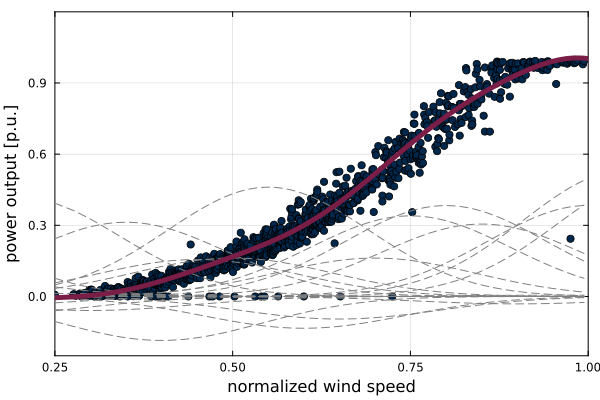

In [ ]:
# 1 
# Example from ECE 598
# RBF-SVM for wind power curve fitting with Tikhonov regularization, wind power data example from ECE 598

purple = RGB(122/256, 30/256, 71/256)
blue   = RGB(0/256, 39/256, 76/256)
mygreen = RGB(83/256, 165/256, 132/256)

dataset = JSON.parsefile("wind_power_data.json")

n = length(dataset["ActivePower"])

sort_index = sortperm(dataset["WindSpeed"])

t = Float64.(dataset["ActivePower"][sort_index])

x_raw = Float64.(dataset["WindSpeed"][sort_index])
x = x_raw ./ 10.0

# Parameters
α = 0.01          # learning rate
iter_max = 25_000 # maximum iterations
λ = 0.001         # regularization coefficient

reg_type = "l2"

c = collect(0.0:0.05:1.1)

num_centers = length(c)

γ = 5.0

# Gaussian RBF
function φ(x, j)
    return exp(-(γ * abs(x - c[j]))^2)
end


Φ = zeros(n, num_centers)

for i in 1:n
    for j in 1:num_centers
        Φ[i, j] = φ(x[i], j)
    end
end

Random.seed!(128)

w_0 = rand()

w = rand(num_centers)

# Stochastic Gradient Descent
for iteration in 1:iter_max

    # Randomly select one training sample
    i = rand(1:n)

    # RBF values for selected sample
    ϕi = Φ[i, :]

    y_hat = w_0 + dot(ϕi, w)

    # Error
    error = y_hat - t[i]

    # Intercept
    w_0 -= α * error

    # RBF weights
    for j in 1:num_centers
        w[j] -= α * error * ϕi[j]
    end

    if reg_type == "l2"

        # Do not regularize the intercept
        w .-= α * λ .* w

    elseif reg_type == "l1"

        # L1 regularization on RBF weights
        w .= sign.(w) .* max.(0, abs.(w) .- α * λ)

    end

end

function w̅(x_value)
    return w_0 + sum(w[j] * φ(x_value, j)
                     for j in 1:num_centers)
end

prediction = w_0 .+ Φ * w


plo = scatter(x,t,c = blue,frame = :box,label = false,xlabel = "normalized wind speed",ylabel = "power output [p.u.]")
plot!(plo,ylims = (-0.25, 1.2),xlims = (0.25, 1.0))

for j in 1:num_centers
    plot!(plo,x,w[j] .* Φ[:, j],c = :gray,label = false,linestyle = :dash)
end

plot!(plo,x,fill(w_0, length(x)),c = :gray,label = false,linestyle = :dash)
plot!(plo,w̅,0.25,1.0,lw = 5,c = purple,label = false)

display(plo)


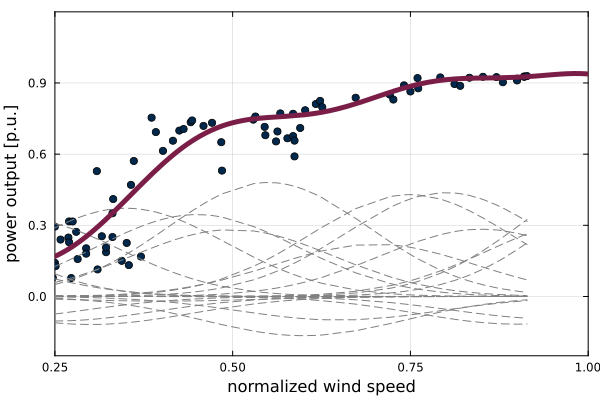

In [ ]:
# 2 
# Example from 598 with new data
# RBF-SVM for wind power curve fitting with Tikhonov regularization, wind power from kaggle data set, no data set split, windspeed 10m only feature

purple = RGB(122/256, 30/256, 71/256)
blue   = RGB(0/256, 39/256, 76/256)
mygreen = RGB(83/256, 165/256, 132/256)

df = CSV.read("location1.csv", DataFrame; limit = 96)  

n = nrow(df)

sort_index = sortperm(df.windspeed_10m)

t = Float64.(df.Power[sort_index])

x_raw = Float64.(df.windspeed_10m[sort_index])
x = x_raw ./ 10.0

# Parameters
α = 0.01          # learning rate
iter_max = 25_000 # maximum iterations
λ = 0.001         # regularization coefficient

reg_type = "l2"

c = collect(0.0:0.05:1.1)

num_centers = length(c)

γ = 5.0

# Gaussian RBF
function φ(x, j)
    return exp(-(γ * abs(x - c[j]))^2)
end


Φ = zeros(n, num_centers)

for i in 1:n
    for j in 1:num_centers
        Φ[i, j] = φ(x[i], j)
    end
end

Random.seed!(128)

w_0 = rand()

w = rand(num_centers)

# Stochastic Gradient Descent
for iteration in 1:iter_max

    # Randomly select one training sample
    i = rand(1:n)

    # RBF values for selected sample
    ϕi = Φ[i, :]

    y_hat = w_0 + dot(ϕi, w)

    # Error
    error = y_hat - t[i]

    # Intercept
    w_0 -= α * error

    # RBF weights
    for j in 1:num_centers
        w[j] -= α * error * ϕi[j]
    end

    if reg_type == "l2"

        # Do not regularize the intercept
        w .-= α * λ .* w

    elseif reg_type == "l1"

        # L1 regularization on RBF weights
        w .= sign.(w) .* max.(0, abs.(w) .- α * λ)

    end

end

function w̅(x_value)
    return w_0 + sum(w[j] * φ(x_value, j)
                     for j in 1:num_centers)
end

prediction = w_0 .+ Φ * w

plo = scatter(x,t,c = blue,frame = :box,label = false,xlabel = "normalized wind speed",ylabel = "power output [p.u.]")
plot!(plo,ylims = (-0.25, 1.2),xlims = (0.25, 1.0))

for j in 1:num_centers
    plot!(plo,x,w[j] .* Φ[:, j],c = :gray,label = false,linestyle = :dash)
end

plot!(plo,x,fill(w_0, length(x)),c = :gray,label = false,linestyle = :dash)
plot!(plo,w̅,0.25,1.0,lw = 5,c = purple,label = false)

display(plo)


γ = 2.0, λ = 1.0e-5 → val RMSE = 0.1697
γ = 2.0, λ = 0.0001 → val RMSE = 0.1696
γ = 2.0, λ = 0.001 → val RMSE = 0.1688
γ = 2.0, λ = 0.01 → val RMSE = 0.1659
γ = 2.0, λ = 0.1 → val RMSE = 0.1583
γ = 5.0, λ = 1.0e-5 → val RMSE = 0.1681
γ = 5.0, λ = 0.0001 → val RMSE = 0.1679
γ = 5.0, λ = 0.001 → val RMSE = 0.1669
γ = 5.0, λ = 0.01 → val RMSE = 0.164
γ = 5.0, λ = 0.1 → val RMSE = 0.1601
γ = 10.0, λ = 1.0e-5 → val RMSE = 0.1532
γ = 10.0, λ = 0.0001 → val RMSE = 0.1531
γ = 10.0, λ = 0.001 → val RMSE = 0.1523
γ = 10.0, λ = 0.01 → val RMSE = 0.1528
γ = 10.0, λ = 0.1 → val RMSE = 0.1603
Best: (rmse = 0.15228833157446298, λ = 0.001, γ = 10.0)
Test RMSE = 0.15907455425115236


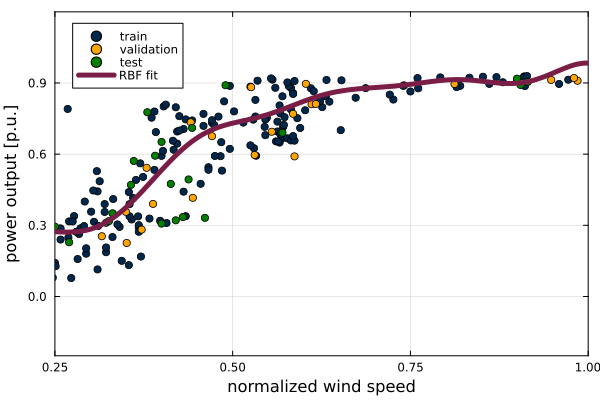

In [ ]:
# 3 
#Example with new data, training/validation/testing split
# Data from the kaggle data set sorted by wind speed, data set split into training, validation, testing, windspeed 10m only feature

purple = RGB(122/256, 30/256, 71/256)
blue   = RGB(0/256, 39/256, 76/256)

df = CSV.read("location1.csv", DataFrame; limit = 240)
n  = nrow(df)

sort_index = sortperm(df.windspeed_10m)
t = Float64.(df.Power[sort_index])
x = Float64.(df.windspeed_10m[sort_index]) ./ 10.0

train, val, test = partition(eachindex(t), 0.8, 0.1; shuffle = true, rng = 128)

c = collect(0.0:0.05:1.1)
num_centers = length(c)

# Gaussian function
function design_matrix(xs, γ)
    Φ = zeros(length(xs), num_centers)
    for i in eachindex(xs), j in 1:num_centers
        Φ[i, j] = exp(-(γ * abs(xs[i] - c[j]))^2)
    end
    return Φ
end

function train_rbf(Φ, t; α = 0.01, iter_max = 25_000, λ = 0.001,
                   reg_type = "l2", seed = 128)
    rng = MersenneTwister(seed)
    ntrain = size(Φ, 1)
    w_0 = rand(rng)
    w   = rand(rng, num_centers)

    for _ in 1:iter_max
        i  = rand(rng, 1:ntrain)       # sample ONLY from the training rows
        ϕi = Φ[i, :]
        err = (w_0 + dot(ϕi, w)) - t[i]

        w_0 -= α * err
        w   .-= α * err .* ϕi

        if reg_type == "l2"
            w .-= α * λ .* w
        elseif reg_type == "l1"
            w .= sign.(w) .* max.(0, abs.(w) .- α * λ)
        end
    end
    return w_0, w
end

predict_rbf(Φ, w_0, w) = w_0 .+ Φ * w

# ---------- Hyperparameter selection on the validation set ----------
λ_grid = [1e-5, 1e-4, 1e-3, 1e-2, 1e-1]
γ_grid = [2.0, 5.0, 10.0]

best = (rmse = Inf, λ = NaN, γ = NaN)
for γ in γ_grid, λ in λ_grid
    Φ_train = design_matrix(x[train], γ)
    Φ_val   = design_matrix(x[val],   γ)
    w_0, w  = train_rbf(Φ_train, t[train]; λ = λ)
    score   = rmse(predict_rbf(Φ_val, w_0, w), t[val])
    println("γ = $γ, λ = $λ → val RMSE = $(round(score, digits = 4))")
    if score < best.rmse
        global best = (rmse = score, λ = λ, γ = γ)
    end
end
println("Best: ", best)

# ---------- Final fit and test evaluation ----------
γ, λ = best.γ, best.λ

Φ_train = design_matrix(x[train], γ)
w_0, w  = train_rbf(Φ_train, t[train]; λ = λ)

Φ_test = design_matrix(x[test], γ)
println("Test RMSE = ", rmse(predict_rbf(Φ_test, w_0, w), t[test]))

# ---------- Plot ----------
φ(xv, j) = exp(-(γ * abs(xv - c[j]))^2)
w̅(xv) = w_0 + sum(w[j] * φ(xv, j) for j in 1:num_centers)

plo = scatter(x[train], t[train], c = blue,   label = "train", frame = :box,
              xlabel = "normalized wind speed", ylabel = "power output [p.u.]")
scatter!(plo, x[val],  t[val],  c = :orange, label = "validation")
scatter!(plo, x[test], t[test], c = :green,  label = "test")
plot!(plo, w̅, 0.25, 1.0, lw = 5, c = purple, label = "RBF fit")
plot!(plo, ylims = (-0.25, 1.2), xlims = (0.25, 1.0))
display(plo)

["2017-01-02 00:00:00", "2017-01-02 01:00:00", "2017-01-02 02:00:00"]
γ = 5.0, λ = 0.0005 → val RMSE = 0.1711
γ = 5.0, λ = 0.0002 → val RMSE = 0.1711
γ = 5.0, λ = 0.0001 → val RMSE = 0.1711
γ = 5.0, λ = 7.5e-5 → val RMSE = 0.1711
γ = 5.0, λ = 5.0e-5 → val RMSE = 0.1711
γ = 6.0, λ = 0.0005 → val RMSE = 0.1705
γ = 6.0, λ = 0.0002 → val RMSE = 0.1705
γ = 6.0, λ = 0.0001 → val RMSE = 0.1705
γ = 6.0, λ = 7.5e-5 → val RMSE = 0.1705
γ = 6.0, λ = 5.0e-5 → val RMSE = 0.1705
γ = 7.0, λ = 0.0005 → val RMSE = 0.1704
γ = 7.0, λ = 0.0002 → val RMSE = 0.1704
γ = 7.0, λ = 0.0001 → val RMSE = 0.1704
γ = 7.0, λ = 7.5e-5 → val RMSE = 0.1704
γ = 7.0, λ = 5.0e-5 → val RMSE = 0.1704
γ = 7.5, λ = 0.0005 → val RMSE = 0.1705
γ = 7.5, λ = 0.0002 → val RMSE = 0.1705
γ = 7.5, λ = 0.0001 → val RMSE = 0.1705
γ = 7.5, λ = 7.5e-5 → val RMSE = 0.1705
γ = 7.5, λ = 5.0e-5 → val RMSE = 0.1705
γ = 8.0, λ = 0.0005 → val RMSE = 0.1707
γ = 8.0, λ = 0.0002 → val RMSE = 0.1707
γ = 8.0, λ = 0.0001 → val RMSE = 0.1707
γ = 8.0, λ

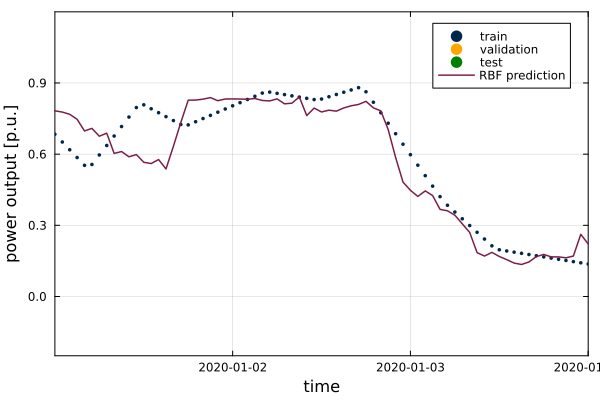

In [ ]:
# 4 
# Example with new data, data split, time sorting
# Data from the kaggle data set sorted by time, data set split into training, validation, testing, multiple wind features

df = CSV.read("location1.csv", DataFrame; types = Dict(:Time => String))
println(first(df.Time, 3))   

df.Time = DateTime.(df.Time, dateformat"yyyy-mm-dd HH:MM:SS")
sort!(df, :Time)

times = df.Time
t     = Float64.(df.Power)
x10m  = Float64.(df.windspeed_10m)  ./ 10.0
x100m = Float64.(df.windspeed_100m) ./ 10.0
x10g  = Float64.(df.windgusts_10m) ./ 10.0

c_max = max(1.1, maximum(x10m), maximum(x100m)) + 0.05
c = collect(0.0:0.05:c_max)
num_centers = length(c)

# RBF features for one input
function rbf_features(xs, γ)
    Φ = zeros(length(xs), num_centers)
    for i in eachindex(xs), j in 1:num_centers
        Φ[i, j] = exp(-(γ * abs(xs[i] - c[j]))^2)
    end
    return Φ
end

design_matrix(x1, x2, x3, γ) = hcat(rbf_features(x1, γ), rbf_features(x2, γ), rbf_features(x3, γ))

function train_rbf(Φ, t; α = 0.01, n_epochs = 20, λ = 0.001,
                   reg_type = :l2, seed = 128)
    reg_type in (:l2, :l1, :none) ||
        error("reg_type must be :l2, :l1, or :none, got $reg_type")

    rng    = MersenneTwister(seed)
    ntrain = size(Φ, 1)
    nfeat  = size(Φ, 2)
    w_0    = 0.0
    w      = zeros(nfeat)

    for epoch in 1:n_epochs
        for i in shuffle(rng, 1:ntrain)       # each sample visited once per epoch
            ϕi  = @view Φ[i, :]               # no allocation
            err = (w_0 + dot(ϕi, w)) - t[i]

            w_0 -= α * err
            w   .-= α * err .* ϕi

            if reg_type == :l2
                w .-= α * λ .* w
            elseif reg_type == :l1
                w .= sign.(w) .* max.(0, abs.(w) .- α * λ)
            end
        end
    end
    return w_0, w
end

predict_rbf(Φ, w_0, w) = w_0 .+ Φ * w

# ---------- Hyperparameter selection on the validation set ----------
λ_grid = [5e-4, 2e-4, 1e-4, 7.5e-5, 5e-5]
γ_grid = [ 5.0, 6.0, 7.0, 7.5, 8.0, 8.5]

best = (rmse = Inf, λ = NaN, γ = NaN)
for γ in γ_grid, λ in λ_grid
    Φ_train = design_matrix(x10m[train], x100m[train], x10g[train], γ)
    Φ_val   = design_matrix(x10m[val],   x100m[val], x10g[val],  γ)
    w_0, w  = train_rbf(Φ_train, t[train]; λ = λ)
    score   = rmse(predict_rbf(Φ_val, w_0, w), t[val])
    println("γ = $γ, λ = $λ → val RMSE = $(round(score, digits = 4))")
    if score < best.rmse
        global best = (rmse = score, λ = λ, γ = γ)
    end
end
println("Best: ", best)

# ---------- Final fit and test evaluation ----------
γ, λ = best.γ, best.λ

Φ_train = design_matrix(x10m[train], x100m[train], x10g[train], γ)
w_0, w  = train_rbf(Φ_train, t[train]; λ = λ)

Φ_test = design_matrix(x10m[test], x100m[test], x10g[test], γ)

# ---------- Plot (by time) ----------
ŷ = predict_rbf(design_matrix(x10m, x100m, x10g, γ), w_0, w)   # one prediction per timestamp

plo = scatter(times[train], t[train], c = blue, label = "train",ms = 2, markerstrokewidth = 0, frame = :box,xlabel = "time", ylabel = "power output [p.u.]")
scatter!(plo, times[val],  t[val],  c = :orange, ms = 2, markerstrokewidth = 0, label = "validation")
scatter!(plo, times[test], t[test], c = :green,  ms = 2, markerstrokewidth = 0, label = "test")
plot!(plo, times, ŷ, lw = 1.5, c = purple, label = "RBF prediction")
plot!(plo, ylims = (-0.25, 1.2))

# Zoom into two weeks if the data spans a long period (adjust the year):
plot!(plo, xlims = (DateTime(2020, 1, 1), DateTime(2020, 1, 4)))

display(plo)

["2017-01-02 00:00:00", "2017-01-02 01:00:00", "2017-01-02 02:00:00"]
Option B: λ = 0.01 → val RMSE = 0.172
Option B: λ = 0.1 → val RMSE = 0.171
Option B: λ = 1.0 → val RMSE = 0.1687
Option B: λ = 10.0 → val RMSE = 0.1674
Option B: λ = 100.0 → val RMSE = 0.1722
Best (Option B): (rmse = 0.16740165279142719, λ = 10.0)
Option B test RMSE: 0.162
Mean per-day test RMSE: A = 0.1502, B = 0.1405


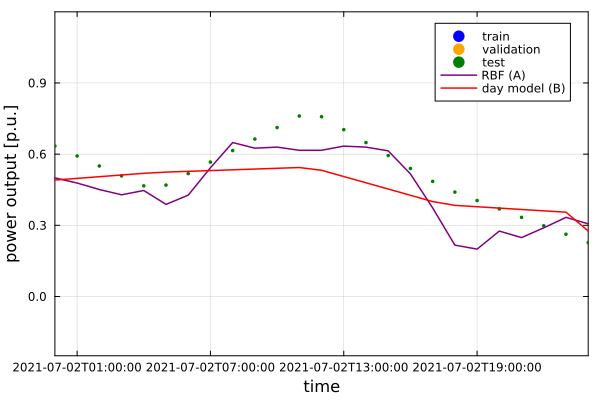

In [ ]:
# Data split, three features, prediction by day
rmse(a, b) = sqrt(mean((a .- b) .^ 2))
steps_per_day = 24     

df = CSV.read("location1.csv", DataFrame; types = Dict(:Time => String))
println(first(df.Time, 3))  

df.Time = DateTime.(df.Time, dateformat"yyyy-mm-dd HH:MM:SS")
sort!(df, :Time)

df.Date = Date.(df.Time)
counts  = combine(groupby(df, :Date), nrow => :n)
good    = Set(counts.Date[counts.n .== steps_per_day])
df      = df[in.(df.Date, Ref(good)), :]          # still sorted by time

times = df.Time
t     = Float64.(df.Power)
x10m  = Float64.(df.windspeed_10m)  ./ 10.0
x100m = Float64.(df.windspeed_100m) ./ 10.0
x10g  = Float64.(df.windgusts_10m)  ./ 10.0

nd = nrow(df) ÷ steps_per_day                     # number of complete days
day_rows(d)   = ((d-1)*steps_per_day + 1):(d*steps_per_day)
rows_of(days) = reduce(vcat, [collect(day_rows(d)) for d in days])

# Split into days
n_tr  = round(Int, 0.80nd)
n_val = round(Int, 0.10nd)

train_days = 1:n_tr
val_days   = (n_tr+1):(n_tr+n_val)
test_days  = (n_tr+n_val+1):nd

train = rows_of(train_days)
val   = rows_of(val_days)
test  = rows_of(test_days)

# RBF/SGD 
c_max = max(1.1, maximum(x10m), maximum(x100m)) + 0.05
c = collect(0.0:0.05:c_max)
num_centers = length(c)

function rbf_features(xs, γ)
    Φ = zeros(length(xs), num_centers)
    for i in eachindex(xs), j in 1:num_centers
        Φ[i, j] = exp(-(γ * abs(xs[i] - c[j]))^2)
    end
    return Φ
end

design_matrix(x1, x2, x3, γ) = hcat(rbf_features(x1, γ), rbf_features(x2, γ), rbf_features(x3, γ))

# RBF training adjust for full days
function train_rbf_days(Φ, t, days; α = 0.05, n_epochs = 50, λ = 0.001,
                        reg_type = :l1, seed = 128)
    reg_type in (:l2, :l1, :none) ||
        error("reg_type must be :l2, :l1, or :none, got $reg_type")

    rng = MersenneTwister(seed)
    w_0 = 0.0
    w   = zeros(size(Φ, 2))

    for epoch in 1:n_epochs
        for d in shuffle(rng, collect(days))    
            r   = day_rows(d)
            Φd  = @view Φ[r, :]                  
            err = (w_0 .+ Φd * w) .- @view(t[r]) 

            w_0 -= α * mean(err)
            w  .-= α .* (Φd' * err) ./ steps_per_day

            if reg_type == :l2
                w .-= α * λ .* w
            elseif reg_type == :l1
                w .= sign.(w) .* max.(0, abs.(w) .- α * λ)
            end
        end
    end
    return w_0, w
end

predict_rbf(Φ, w_0, w) = w_0 .+ Φ * w


# Validation 
X = zeros(nd, 3steps_per_day)
Y = zeros(nd, steps_per_day)
for d in 1:nd
    r = day_rows(d)
    X[d, :] = vcat(x10m[r], x100m[r], x10g[r])
    Y[d, :] = t[r]
end

function fit_day_model(X, Y, λ)
    Xb = hcat(ones(size(X, 1)), X)
    R  = Matrix{Float64}(λ * I, size(Xb, 2), size(Xb, 2))
    R[1, 1] = 0.0                                  # don't penalize the bias
    return (Xb' * Xb + R) \ (Xb' * Y)              # (1+3*steps) × steps
end
predict_day(X, W) = hcat(ones(size(X, 1)), X) * W

best_day = (rmse = Inf, λ = NaN)
for λb in [1e-2, 1e-1, 1.0, 10.0, 100.0]
    W = fit_day_model(X[train_days, :], Y[train_days, :], λb)
    s = rmse(vec(predict_day(X[val_days, :], W)), vec(Y[val_days, :]))
    println("Option B: λ = $λb → val RMSE = $(round(s, digits = 4))")
    if s < best_day.rmse
        global best_day = (rmse = s, λ = λb)
    end
end
println("Best (Option B): ", best_day)

W   = fit_day_model(X[train_days, :], Y[train_days, :], best_day.λ)
Ŷ   = predict_day(X, W)                            # nd × steps_per_day
ŷ_B = vec(permutedims(Ŷ))                          # flatten back to time order
println("Option B test RMSE: ", round(rmse(vec(Ŷ[test_days, :]), vec(Y[test_days, :])), digits = 4))

# Plot
plo = scatter(times[train], t[train], c = :blue, label = "train",
              ms = 2, markerstrokewidth = 0, frame = :box,
              xlabel = "time", ylabel = "power output [p.u.]")
scatter!(plo, times[val],  t[val],  c = :orange, ms = 2, markerstrokewidth = 0, label = "validation")
scatter!(plo, times[test], t[test], c = :green,  ms = 2, markerstrokewidth = 0, label = "test")
plot!(plo, times, ŷ_B, lw = 1.5, c = :red,    label = "day model (B)")
plot!(plo, ylims = (-0.25, 1.2))

# Zoom into the first 3 test days (adjust as needed):
t0 = times[first(day_rows(first(test_days)))]
plot!(plo, xlims = (t0, t0 + Day(1)))

display(plo)

["2017-01-02 00:00:00", "2017-01-02 01:00:00", "2017-01-02 02:00:00"]
Best: (rmse = 0.15242362664765977, λ = 0.5, γ = 0.1)
Test RMSE: 0.1329


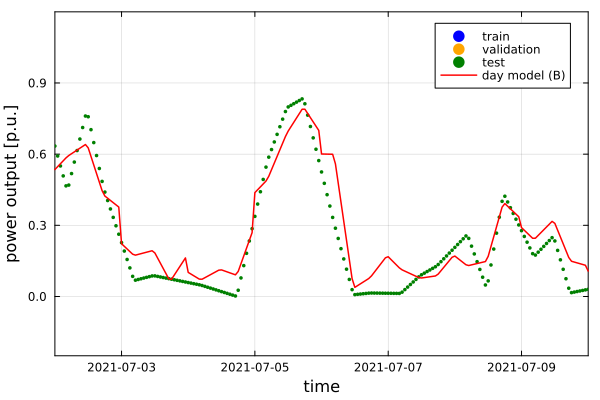

In [39]:
# Data split, three features, prediction by day
rmse(a, b) = sqrt(mean((a .- b) .^ 2))
steps_per_day = 24     

df = CSV.read("location1.csv", DataFrame; types = Dict(:Time => String))
println(first(df.Time, 3))  

df.Time = DateTime.(df.Time, dateformat"yyyy-mm-dd HH:MM:SS")
sort!(df, :Time)

df.Date = Date.(df.Time)
counts  = combine(groupby(df, :Date), nrow => :n)
good    = Set(counts.Date[counts.n .== steps_per_day])
df      = df[in.(df.Date, Ref(good)), :]          # still sorted by time

times = df.Time
t     = Float64.(df.Power)
x10m  = Float64.(df.windspeed_10m)  ./ 10.0
x100m = Float64.(df.windspeed_100m) ./ 10.0
x10g  = Float64.(df.windgusts_10m)  ./ 10.0

nd = nrow(df) ÷ steps_per_day                     # number of complete days
day_rows(d)   = ((d-1)*steps_per_day + 1):(d*steps_per_day)
rows_of(days) = reduce(vcat, [collect(day_rows(d)) for d in days])

# Split into days
n_tr  = round(Int, 0.80nd)
n_val = round(Int, 0.10nd)

train_days = 1:n_tr
val_days   = (n_tr+1):(n_tr+n_val)
test_days  = (n_tr+n_val+1):nd

train = rows_of(train_days)
val   = rows_of(val_days)
test  = rows_of(test_days)

# ---------- Option B: kernel ridge on daily vectors, validate over (γ, λ) ----------
X = zeros(nd, 3steps_per_day)
Y = zeros(nd, steps_per_day)
for d in 1:nd
    r = day_rows(d)
    X[d, :] = vcat(x10m[r], x100m[r], x10g[r])
    Y[d, :] = t[r]
end

# Pairwise squared Euclidean distances between rows of A and rows of B
sqdist(A, B) = max.(sum(abs2, A, dims = 2) .+ sum(abs2, B, dims = 2)' .- 2 .* (A * B'), 0.0)

Xtr, Ytr = X[train_days, :], Y[train_days, :]
Xva, Yva = X[val_days, :],   Y[val_days, :]

# Distances don't depend on γ or λ, so compute once
D_tr = sqdist(Xtr, Xtr)
D_va = sqdist(Xva, Xtr)

μ_Y = mean(Ytr, dims = 1)                       # acts as the bias term

fit_kr(K, Ytr, λ) = (K + λ * I) \ (Ytr .- μ_Y)  # dual weights, ntrain × steps
pred_kr(Kx, A)    = Kx * A .+ μ_Y

γ_grid = [0.01, 0.025, 0.05, 0.1, 0.15, 0.2]
λ_grid = [0.2, 0.5, 1.0, 2.0, 4.0]

val_rmse_B = fill(NaN, length(γ_grid), length(λ_grid))   # rows = γ, cols = λ
best_B = (rmse = Inf, λ = NaN, γ = NaN)

for (iγ, γ) in enumerate(γ_grid)
    K_tr = exp.(-γ .* D_tr)                      # depends only on γ
    K_va = exp.(-γ .* D_va)

    for (iλ, λ) in enumerate(λ_grid)
        A = fit_kr(K_tr, Ytr, λ)
        s = rmse(vec(pred_kr(K_va, A)), vec(Yva))
        val_rmse_B[iγ, iλ] = s
        if s < best_B.rmse
            global best_B = (rmse = s, λ = λ, γ = γ)
        end
    end
end
println("Best: ", best_B)

# ---------- Final fit and test evaluation ----------
γ_B, λ_B = best_B.γ, best_B.λ
A  = fit_kr(exp.(-γ_B .* D_tr), Ytr, λ_B)
Ŷ  = pred_kr(exp.(-γ_B .* sqdist(X, Xtr)), A)    # nd × steps_per_day
ŷ_B = vec(permutedims(Ŷ))                        # flatten back to time order

println("Test RMSE: ",
        round(rmse(vec(Ŷ[test_days, :]), vec(Y[test_days, :])), digits = 4))
# ---------- Plot ----------
plo = scatter(times[train], t[train], c = :blue, label = "train",
              ms = 2, markerstrokewidth = 0, frame = :box,
              xlabel = "time", ylabel = "power output [p.u.]")
scatter!(plo, times[val],  t[val],  c = :orange, ms = 2, markerstrokewidth = 0, label = "validation")
scatter!(plo, times[test], t[test], c = :green,  ms = 2, markerstrokewidth = 0, label = "test")
plot!(plo, times, ŷ_B, lw = 1.5, c = :red, label = "day model (B)")
plot!(plo, ylims = (-0.25, 1.2))

t0 = times[first(day_rows(first(test_days)))]
plot!(plo, xlims = (t0, t0 + Day(8)))

display(plo)

["2017-01-02 00:00:00", "2017-01-02 01:00:00", "2017-01-02 02:00:00"]
Best: (rmse = 0.17888995179929038, α = 0.01, λ = 0.0001, γ = 10.0)
Test RMSE: 0.1631


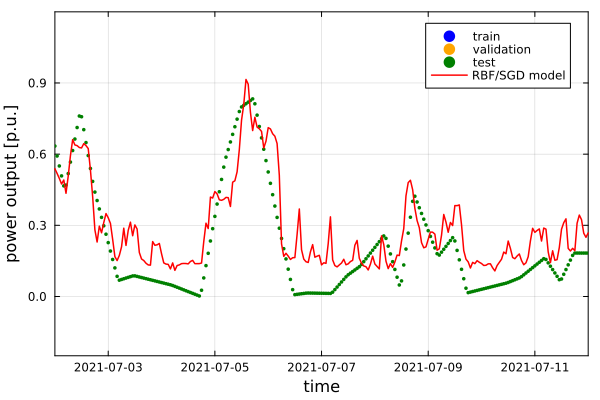

In [ ]:
# Data split, three features, prediction by day
# RBF features + SGD (ridge / L2 penalty), validated over (γ, λ)

rmse(a, b) = sqrt(mean((a .- b) .^ 2))
steps_per_day = 24

df = CSV.read("location1.csv", DataFrame; types = Dict(:Time => String))
println(first(df.Time, 3))

df.Time = DateTime.(df.Time, dateformat"yyyy-mm-dd HH:MM:SS")
sort!(df, :Time)

df.Date = Date.(df.Time)
counts  = combine(groupby(df, :Date), nrow => :n)
good    = Set(counts.Date[counts.n .== steps_per_day])
df      = df[in.(df.Date, Ref(good)), :]          # still sorted by time

times = df.Time
t     = Float64.(df.Power)
x10m  = Float64.(df.windspeed_10m)  ./ 10.0
x100m = Float64.(df.windspeed_100m) ./ 10.0
x10g  = Float64.(df.windgusts_10m)  ./ 10.0

nd = nrow(df) ÷ steps_per_day                     # number of complete days
day_rows(d)   = ((d-1)*steps_per_day + 1):(d*steps_per_day)
rows_of(days) = reduce(vcat, [collect(day_rows(d)) for d in days])

# Split into days
n_tr  = round(Int, 0.80nd)
n_val = round(Int, 0.10nd)

train_days = 1:n_tr
val_days   = (n_tr+1):(n_tr+n_val)
test_days  = (n_tr+n_val+1):nd

train = rows_of(train_days)
val   = rows_of(val_days)
test  = rows_of(test_days)

# ---------- RBF features ----------
c = collect(0.0:0.05:1.1)
num_centers = length(c)

function rbf_features(xs, γ)
    Φ = zeros(length(xs), num_centers)
    for i in eachindex(xs), j in 1:num_centers
        Φ[i, j] = exp(-(γ * abs(xs[i] - c[j]))^2)
    end
    return Φ
end

design_matrix(x1, x2, x3, γ) = hcat(rbf_features(x1, γ), rbf_features(x2, γ), rbf_features(x3, γ))

# ---------- SGD training, one full day per step ----------
function train_rbf_days(Φ, t, days; α = 0.001, n_epochs = 50, λ = 0.001,
                        reg_type = :l1, seed = 128)
    reg_type in (:l2, :l1, :none) ||
        error("reg_type must be :l2, :l1, or :none, got $reg_type")

    rng = MersenneTwister(seed)
    w_0 = 0.0
    w   = zeros(size(Φ, 2))

    for epoch in 1:n_epochs
        for d in shuffle(rng, collect(days))
            r   = day_rows(d)
            Φd  = @view Φ[r, :]
            err = (w_0 .+ Φd * w) .- @view(t[r])

            w_0 -= α * mean(err)                       # intercept, not regularized
            w  .-= α .* (Φd' * err) ./ steps_per_day

            if reg_type == :l2
                w .-= α * λ .* w
            elseif reg_type == :l1
                w .= sign.(w) .* max.(0, abs.(w) .- α * λ)
            end
        end
    end
    return w_0, w
end

predict_rbf(Φ, w_0, w) = w_0 .+ Φ * w

# ---------- Validate over (γ, λ) ----------
γ_grid = [0.01, 0.1, 1, 10, 100]
λ_grid = [1e-4, 1e-3, 1e-2, 1e-1, 1.0, 10.0]
α_grid = [0.001, 0.01, 0.1, 1.0, 10]
 
val_rmse = fill(NaN, length(γ_grid), length(λ_grid), length(α_grid))  # dims = γ, λ, α
best = (rmse = Inf, α = NaN, λ = NaN, γ = NaN)
 
for (iγ, γ) in enumerate(γ_grid)
    Φ = design_matrix(x10m, x100m, x10g, γ)            # depends only on γ
 
    for (iλ, λ) in enumerate(λ_grid), (iα, α) in enumerate(α_grid)
        w_0, w = train_rbf_days(Φ, t, train_days; α = α, λ = λ, reg_type = :l2)
        s = rmse(predict_rbf(Φ[val, :], w_0, w), t[val])
        val_rmse[iγ, iλ, iα] = s
        if s < best.rmse
            global best = (rmse = s, α = α, λ = λ, γ = γ)
        end
    end
end
println("Best: ", best)

# ---------- Final fit and test evaluation ----------
γ_best, λ_best = best.γ, best.λ
Φ_all = design_matrix(x10m, x100m, x10g, γ_best)
w_0, w = train_rbf_days(Φ_all, t, train_days; λ = λ_best, reg_type = :l2)
ŷ = predict_rbf(Φ_all, w_0, w)

println("Test RMSE: ", round(rmse(ŷ[test], t[test]), digits = 4))

# ---------- Plot ----------
plo = scatter(times[train], t[train], c = :blue, label = "train",
              ms = 2, markerstrokewidth = 0, frame = :box,
              xlabel = "time", ylabel = "power output [p.u.]")
scatter!(plo, times[val],  t[val],  c = :orange, ms = 2, markerstrokewidth = 0, label = "validation")
scatter!(plo, times[test], t[test], c = :green,  ms = 2, markerstrokewidth = 0, label = "test")
plot!(plo, times, ŷ, lw = 1.5, c = :red, label = "RBF/SGD model")
plot!(plo, ylims = (-0.25, 1.2))

t0 = times[first(day_rows(first(test_days)))]
plot!(plo, xlims = (t0, t0 + Day(1)))

display(plo)

["2017-01-02 00:00:00", "2017-01-02 01:00:00", "2017-01-02 02:00:00"]
Best: (rmse = 0.16688603791612405, α = 0.5, λ = 0.0001, γ = 0.05)
Test RMSE: 0.151


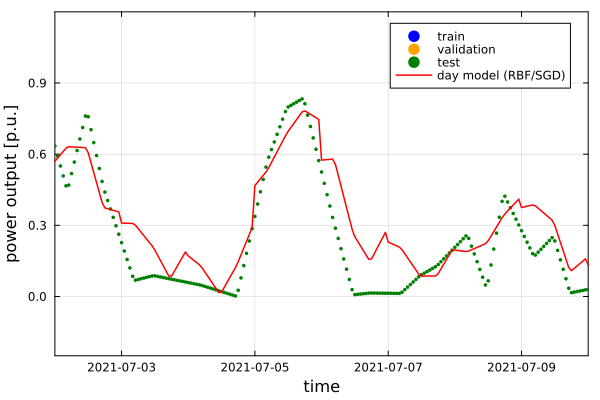

In [51]:
using CSV, DataFrames, Dates, Statistics, Random, Plots

# Data split, three features, prediction by day
# RBF features on whole-day vectors, fit by SGD with an L2 (ridge) penalty

rmse(a, b) = sqrt(mean((a .- b) .^ 2))
steps_per_day = 24

df = CSV.read("location1.csv", DataFrame; types = Dict(:Time => String))
println(first(df.Time, 3))

df.Time = DateTime.(df.Time, dateformat"yyyy-mm-dd HH:MM:SS")
sort!(df, :Time)

df.Date = Date.(df.Time)
counts  = combine(groupby(df, :Date), nrow => :n)
good    = Set(counts.Date[counts.n .== steps_per_day])
df      = df[in.(df.Date, Ref(good)), :]          # still sorted by time

times = df.Time
t     = Float64.(df.Power)
x10m  = Float64.(df.windspeed_10m)  ./ 10.0
x100m = Float64.(df.windspeed_100m) ./ 10.0
x10g  = Float64.(df.windgusts_10m)  ./ 10.0

nd = nrow(df) ÷ steps_per_day                     # number of complete days
day_rows(d)   = ((d-1)*steps_per_day + 1):(d*steps_per_day)
rows_of(days) = reduce(vcat, [collect(day_rows(d)) for d in days])

# Split into days
n_tr  = round(Int, 0.80nd)
n_val = round(Int, 0.10nd)

train_days = 1:n_tr
val_days   = (n_tr+1):(n_tr+n_val)
test_days  = (n_tr+n_val+1):nd

train = rows_of(train_days)
val   = rows_of(val_days)
test  = rows_of(test_days)

# ---------- Daily vectors: one row per day ----------
X = zeros(nd, 3steps_per_day)
Y = zeros(nd, steps_per_day)
for d in 1:nd
    r = day_rows(d)
    X[d, :] = vcat(x10m[r], x100m[r], x10g[r])
    Y[d, :] = t[r]
end

# Pairwise squared Euclidean distances between rows of A and rows of B
sqdist(A, B) = max.(sum(abs2, A, dims = 2) .+ sum(abs2, B, dims = 2)' .- 2 .* (A * B'), 0.0)

Xtr, Ytr = X[train_days, :], Y[train_days, :]
Yva      = Y[val_days, :]

# RBF centers = the training days (a 72-dim input can't use a grid of centers).
# Distances from every day to every center; they don't depend on γ, α, or λ.
D_all = sqdist(X, Xtr)                           # nd × n_tr
D_tr  = D_all[train_days, :]
D_va  = D_all[val_days, :]

num_centers = n_tr
μ_Y = mean(Ytr, dims = 1)                        # initial / unpenalized bias, 1 × steps

# Feature matrix: Φ[d, j] = exp(-γ ‖x_d - c_j‖²), scaled so ‖φ‖² ≤ 1.
# The scaling keeps SGD stable for step sizes up to about 1.
rbf_features(D, γ) = exp.(-γ .* D) ./ sqrt(num_centers)

# ---------- SGD training, one day per step ----------
# Model: ŷ_d = b + Wᵀ φ_d, with b ∈ R^24 and W ∈ R^(num_centers × 24)
function train_rbf_sgd(Φ, Y; α = 0.1, n_epochs = 200, λ = 0.001,
                       seed = 128, batch = 32)
    rng = MersenneTwister(seed)
    b = vec(copy(μ_Y))
    W = zeros(size(Φ, 2), size(Y, 2))
    n = size(Φ, 1)

    for epoch in 1:n_epochs
        idx = shuffle(rng, 1:n)
        for s in 1:batch:n
            ib  = idx[s:min(s + batch - 1, n)]
            Φb  = Φ[ib, :]
            err = (Φb * W .+ b') .- Y[ib, :]

            b .-= α .* vec(mean(err, dims = 1))
            W .-= α .* (Φb' * err) ./ length(ib)
            W .*= (1 - α * λ)
        end
    end
    return b, W
end

predict_rbf(Φ, b, W) = Φ * W .+ b'

# ---------- Validate over (γ, λ, α) ----------
γ_grid = [0.01, 0.025, 0.05, 0.1, 0.15, 0.2]
λ_grid = [1e-4, 1e-3, 1e-2, 1e-1]
α_grid = [0.1, 0.3, 0.5]

val_rmse = fill(NaN, length(γ_grid), length(λ_grid), length(α_grid))  # dims = γ, λ, α
best = (rmse = Inf, α = NaN, λ = NaN, γ = NaN)

for (iγ, γ) in enumerate(γ_grid)
    Φ_tr = rbf_features(D_tr, γ)                 # depends only on γ
    Φ_va = rbf_features(D_va, γ)

    for (iλ, λ) in enumerate(λ_grid), (iα, α) in enumerate(α_grid)
        b, W = train_rbf_sgd(Φ_tr, Ytr; α = α, λ = λ)
        s = rmse(vec(predict_rbf(Φ_va, b, W)), vec(Yva))
        val_rmse[iγ, iλ, iα] = s
        if s < best.rmse
            global best = (rmse = s, α = α, λ = λ, γ = γ)
        end
    end
end
println("Best: ", best)

# ---------- Final fit and test evaluation ----------
γ_best, λ_best, α_best = best.γ, best.λ, best.α
b, W = train_rbf_sgd(rbf_features(D_tr, γ_best), Ytr; α = α_best, λ = λ_best)

Ŷ  = predict_rbf(rbf_features(D_all, γ_best), b, W)   # nd × steps_per_day
ŷ  = vec(permutedims(Ŷ))                              # flatten back to time order

println("Test RMSE: ",
        round(rmse(vec(Ŷ[test_days, :]), vec(Y[test_days, :])), digits = 4))

# ---------- Plot ----------
plo = scatter(times[train], t[train], c = :blue, label = "train",
              ms = 2, markerstrokewidth = 0, frame = :box,
              xlabel = "time", ylabel = "power output [p.u.]")
scatter!(plo, times[val],  t[val],  c = :orange, ms = 2, markerstrokewidth = 0, label = "validation")
scatter!(plo, times[test], t[test], c = :green,  ms = 2, markerstrokewidth = 0, label = "test")
plot!(plo, times, ŷ, lw = 1.5, c = :red, label = "day model (RBF/SGD)")
plot!(plo, ylims = (-0.25, 1.2))

t0 = times[first(day_rows(first(test_days)))]
plot!(plo, xlims = (t0, t0 + Day(8)))

display(plo)